In [1]:
pip install pandas numpy scikit-learn xgboost streamlit plotly matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
pip list

Package                   Version
------------------------- -----------
altair                    6.2.2
anyio                     4.13.0
argon2-cffi               25.1.0
argon2-cffi-bindings      25.1.0
arrow                     1.4.0
asttokens                 3.0.1
async-lru                 2.3.0
attrs                     26.1.0
audioop-lts               0.2.2
babel                     2.18.0
beautifulsoup4            4.14.3
bleach                    6.3.0
blinker                   1.9.0
certifi                   2026.5.20
cffi                      2.0.0
charset-normalizer        3.4.7
click                     8.4.2
colorama                  0.4.6
comm                      0.2.3
comtypes                  1.4.16
contourpy                 1.3.3
cycler                    0.12.1
debugpy                   1.8.20
decorator                 5.3.1
defusedxml                0.7.1
et_xmlfile                2.0.0
executing                 2.2.1
fastjsonschema            2.21.2
Flask             

DATASET LOADED SUCCESSFULLY
Number of Rows    : 10100
Number of Columns : 12

First 5 Rows:


,Machine_ID,Machine_Type,Temperature_C,Vibration_mm_s,RPM,Torque_Nm,Tool_Wear_%,Air_Pressure_bar,Operating_Hours,Power_Consumption_kW,Machine_Failure,Maintenance_Status
0,M100,CNC,82.90,3.16,1270.0,18.36,77.51,6.12,1807.0,12.65,1,Required
1,M020,CNC,76.47,3.11,2869.0,17.69,31.32,5.58,2314.0,17.00,1,Required
2,M015,Lathe,67.85,3.23,1644.0,49.98,37.00,6.43,2058.0,15.25,1,Required
3,M007,CNC,70.75,4.37,2079.0,58.34,70.26,5.64,2596.0,17.49,0,Monitor
4,M009,CNC,69.65,2.15,1966.0,59.04,39.86,6.07,1596.0,18.01,0,Normal



DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 10100 entries, 0 to 10099
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Machine_ID            10100 non-null  str    
 1   Machine_Type          10100 non-null  str    
 2   Temperature_C         10065 non-null  float64
 3   Vibration_mm_s        10069 non-null  float64
 4   RPM                   10075 non-null  float64
 5   Torque_Nm             10070 non-null  float64
 6   Tool_Wear_%           10075 non-null  float64
 7   Air_Pressure_bar      10080 non-null  float64
 8   Operating_Hours       10080 non-null  float64
 9   Power_Consumption_kW  10085 non-null  float64
 10  Machine_Failure       10100 non-null  int64  
 11  Maintenance_Status    10100 non-null  str    
dtypes: float64(8), int64(1), str(3)
memory usage: 1.1 MB

MISSING VALUES
Machine_ID               0
Machine_Type             0
Temperature_C           35
Vibration_mm

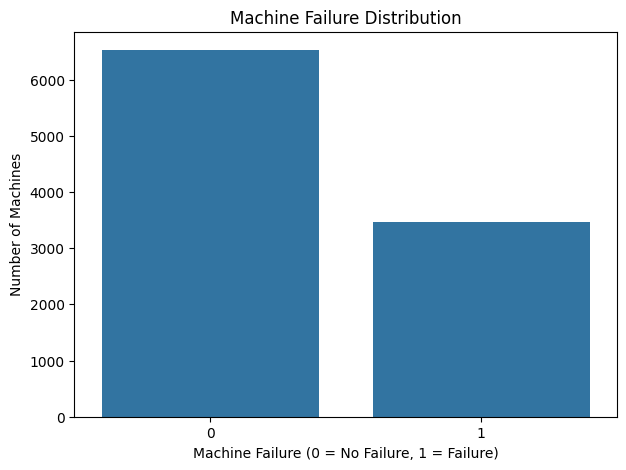


FEATURES AND TARGET
Feature Columns:
['Machine_Type', 'Temperature_C', 'Vibration_mm_s', 'RPM', 'Torque_Nm', 'Tool_Wear_%', 'Air_Pressure_bar', 'Operating_Hours', 'Power_Consumption_kW']

Target Column: Machine_Failure

FEATURE TYPES

Categorical Features:
- Machine_Type

Numerical Features:
- Temperature_C
- Vibration_mm_s
- RPM
- Torque_Nm
- Tool_Wear_%
- Air_Pressure_bar
- Operating_Hours
- Power_Consumption_kW

TRAIN TEST SPLIT
Training Rows: 8000
Testing Rows: 2000

Preprocessing pipeline created successfully.


STARTING MACHINE LEARNING MODEL TRAINING


TRAINING: Logistic Regression
Training completed successfully.

Model Performance:
Accuracy : 0.7085
Precision: 0.6414
Recall   : 0.3655
F1 Score : 0.4656
ROC-AUC  : 0.7257

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.89      0.80      1305
           1       0.64      0.37      0.47       695

    accuracy                           0.71      2000
   macro avg      

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest,0.6730,0.527815,0.559712,0.543296,0.709340
1,XGBoost,0.7075,0.625000,0.395683,0.484581,0.715574
2,Logistic Regression,0.7085,0.641414,0.365468,0.465628,0.725748


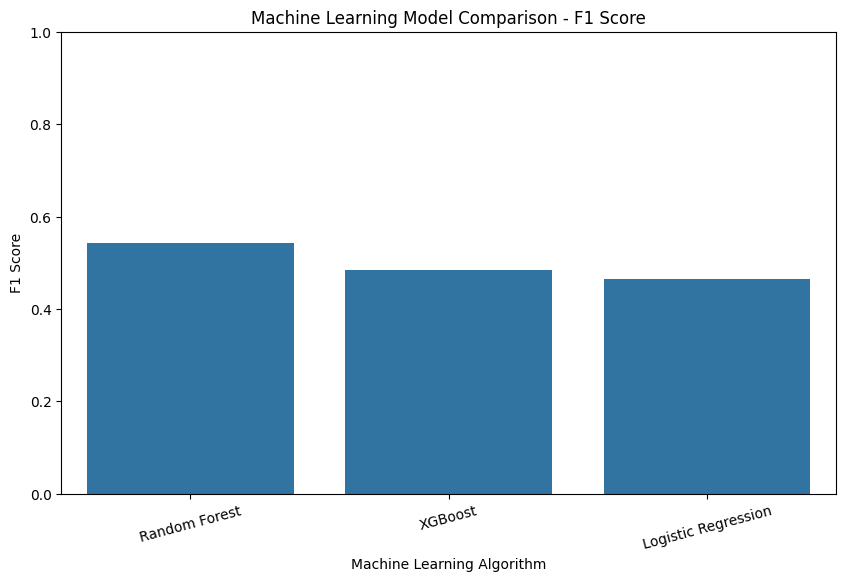



BEST MODEL
Best Model: Random Forest

Best model saved successfully:
models/best_model.pkl
Model comparison saved:
models/model_comparison.csv
Test predictions saved:
models/test_predictions.csv


FINAL MODEL TEST
Predicted Failure: 1
Failure Probability: 51.67 %


MACHINE FAILURE PREDICTION SYSTEM
MODEL TRAINING COMPLETED SUCCESSFULLY

Best Model: Random Forest

Files Created:
1. models/best_model.pkl
2. models/model_comparison.csv
3. models/test_predictions.csv

Ready for Streamlit Dashboard 🚀


In [2]:
# ============================================================
# MACHINE FAILURE PREDICTION SYSTEM
# Complete ML Training Code
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import os
import joblib

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# 2. LOAD UNCLEAN DATASET
# ============================================================

df = pd.read_csv(
    "machine_failure_prediction_dataset.csv"
)

print("=" * 70)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 70)

print("Number of Rows    :", df.shape[0])
print("Number of Columns :", df.shape[1])


# ============================================================
# 3. DISPLAY FIRST 5 ROWS
# ============================================================

print("\nFirst 5 Rows:")
display(df.head())


# ============================================================
# 4. DATASET INFORMATION
# ============================================================

print("\n" + "=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

df.info()


# ============================================================
# 5. CHECK MISSING VALUES
# ============================================================

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

missing_values = df.isnull().sum()

print(missing_values)

print(
    "\nTotal Missing Values:",
    df.isnull().sum().sum()
)


# ============================================================
# 6. CHECK DUPLICATE VALUES
# ============================================================

print("\n" + "=" * 70)
print("DUPLICATE VALUES")
print("=" * 70)

duplicate_count = df.duplicated().sum()

print(
    "Total Duplicate Rows:",
    duplicate_count
)


# ============================================================
# 7. DATASET SHAPE BEFORE CLEANING
# ============================================================

print("\n" + "=" * 70)
print("BEFORE DATA CLEANING")
print("=" * 70)

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])


# ============================================================
# 8. REMOVE DUPLICATE ROWS
# ============================================================

df = df.drop_duplicates()

df = df.reset_index(drop=True)


print("\n" + "=" * 70)
print("AFTER REMOVING DUPLICATES")
print("=" * 70)

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

print(
    "Remaining Duplicates:",
    df.duplicated().sum()
)


# ============================================================
# 9. CHECK TARGET VARIABLE
# ============================================================

print("\n" + "=" * 70)
print("MACHINE FAILURE DISTRIBUTION")
print("=" * 70)

print(
    df["Machine_Failure"].value_counts()
)


print("\nFailure Percentage:")

failure_percentage = (
    df["Machine_Failure"]
    .value_counts(normalize=True)
    * 100
)

print(
    failure_percentage.round(2)
)


# ============================================================
# 10. TARGET VARIABLE VISUALIZATION
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine_Failure"
)

plt.title(
    "Machine Failure Distribution"
)

plt.xlabel(
    "Machine Failure (0 = No Failure, 1 = Failure)"
)

plt.ylabel(
    "Number of Machines"
)

plt.show()


# ============================================================
# 11. DEFINE FEATURES AND TARGET
# ============================================================

# Target variable

y = df["Machine_Failure"]


# Features

X = df.drop(
    columns=[
        "Machine_Failure",
        "Maintenance_Status",
        "Machine_ID"
    ]
)


print("\n" + "=" * 70)
print("FEATURES AND TARGET")
print("=" * 70)

print("Feature Columns:")

print(
    X.columns.tolist()
)

print(
    "\nTarget Column:",
    "Machine_Failure"
)


# ============================================================
# 12. DEFINE CATEGORICAL FEATURES
# ============================================================

categorical_features = [
    "Machine_Type"
]


# ============================================================
# 13. DEFINE NUMERICAL FEATURES
# ============================================================

numerical_features = [

    "Temperature_C",

    "Vibration_mm_s",

    "RPM",

    "Torque_Nm",

    "Tool_Wear_%",

    "Air_Pressure_bar",

    "Operating_Hours",

    "Power_Consumption_kW"

]


# ============================================================
# 14. DISPLAY FEATURE TYPES
# ============================================================

print("\n" + "=" * 70)
print("FEATURE TYPES")
print("=" * 70)

print("\nCategorical Features:")

for column in categorical_features:

    print("-", column)


print("\nNumerical Features:")

for column in numerical_features:

    print("-", column)


# ============================================================
# 15. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)


print("\n" + "=" * 70)
print("TRAIN TEST SPLIT")
print("=" * 70)

print(
    "Training Rows:",
    X_train.shape[0]
)

print(
    "Testing Rows:",
    X_test.shape[0]
)


# ============================================================
# 16. NUMERICAL PREPROCESSING
# ============================================================

numerical_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",

            StandardScaler()
        )

    ]

)


# ============================================================
# 17. CATEGORICAL PREPROCESSING
# ============================================================

categorical_pipeline = Pipeline(

    steps=[

        (
            "imputer",

            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "encoder",

            OneHotEncoder(
                handle_unknown="ignore"
            )
        )

    ]

)


# ============================================================
# 18. COMBINE PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(

    transformers=[

        (
            "numerical",

            numerical_pipeline,

            numerical_features
        ),

        (
            "categorical",

            categorical_pipeline,

            categorical_features
        )

    ]

)


print("\nPreprocessing pipeline created successfully.")


# ============================================================
# 19. LOGISTIC REGRESSION MODEL
# ============================================================

logistic_model = Pipeline(

    steps=[

        (
            "preprocessor",

            preprocessor
        ),

        (
            "model",

            LogisticRegression(

                max_iter=1000,

                random_state=42

            )

        )

    ]

)


# ============================================================
# 20. RANDOM FOREST MODEL
# ============================================================

random_forest_model = Pipeline(

    steps=[

        (
            "preprocessor",

            preprocessor
        ),

        (
            "model",

            RandomForestClassifier(

                n_estimators=200,

                max_depth=12,

                random_state=42,

                class_weight="balanced"

            )

        )

    ]

)


# ============================================================
# 21. XGBOOST MODEL
# ============================================================

xgboost_model = Pipeline(

    steps=[

        (
            "preprocessor",

            preprocessor
        ),

        (
            "model",

            XGBClassifier(

                n_estimators=200,

                max_depth=6,

                learning_rate=0.05,

                subsample=0.8,

                colsample_bytree=0.8,

                eval_metric="logloss",

                random_state=42

            )

        )

    ]

)


# ============================================================
# 22. STORE ALL THREE MODELS
# ============================================================

models = {

    "Logistic Regression":
        logistic_model,

    "Random Forest":
        random_forest_model,

    "XGBoost":
        xgboost_model

}


# ============================================================
# 23. TRAIN ALL MODELS
# ============================================================

results = []

trained_models = {}


print("\n")
print("=" * 70)
print("STARTING MACHINE LEARNING MODEL TRAINING")
print("=" * 70)


for name, model in models.items():


    print("\n")
    print("=" * 70)

    print(
        "TRAINING:",
        name
    )

    print("=" * 70)


    # --------------------------------------------------------
    # Train model
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train
    )


    print(
        "Training completed successfully."
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test
    )


    # --------------------------------------------------------
    # Prediction Probability
    # --------------------------------------------------------

    y_probability = (

        model.predict_proba(
            X_test
        )[:, 1]

    )


    # --------------------------------------------------------
    # Evaluation Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )


    precision = precision_score(

        y_test,

        y_pred,

        zero_division=0

    )


    recall = recall_score(

        y_test,

        y_pred,

        zero_division=0

    )


    f1 = f1_score(

        y_test,

        y_pred,

        zero_division=0

    )


    roc_auc = roc_auc_score(

        y_test,

        y_probability

    )


    # --------------------------------------------------------
    # Display Metrics
    # --------------------------------------------------------

    print("\nModel Performance:")


    print(
        "Accuracy :",
        round(accuracy, 4)
    )


    print(
        "Precision:",
        round(precision, 4)
    )


    print(
        "Recall   :",
        round(recall, 4)
    )


    print(
        "F1 Score :",
        round(f1, 4)
    )


    print(
        "ROC-AUC  :",
        round(roc_auc, 4)
    )


    # --------------------------------------------------------
    # Classification Report
    # --------------------------------------------------------

    print("\nClassification Report:")


    print(

        classification_report(

            y_test,

            y_pred,

            zero_division=0

        )

    )


    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------

    print("\nConfusion Matrix:")


    cm = confusion_matrix(

        y_test,

        y_pred

    )


    print(cm)


    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    results.append({

        "Model":
            name,

        "Accuracy":
            accuracy,

        "Precision":
            precision,

        "Recall":
            recall,

        "F1_Score":
            f1,

        "ROC_AUC":
            roc_auc

    })


    # Store trained model

    trained_models[name] = model


# ============================================================
# 24. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(
    results
)


results_df = results_df.sort_values(

    by="F1_Score",

    ascending=False

)


results_df = results_df.reset_index(
    drop=True
)


print("\n")
print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)


display(
    results_df
)


# ============================================================
# 25. MODEL COMPARISON GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)


sns.barplot(

    data=results_df,

    x="Model",

    y="F1_Score"

)


plt.title(
    "Machine Learning Model Comparison - F1 Score"
)


plt.xlabel(
    "Machine Learning Algorithm"
)


plt.ylabel(
    "F1 Score"
)


plt.ylim(
    0,
    1
)


plt.xticks(
    rotation=15
)


plt.show()


# ============================================================
# 26. SELECT BEST MODEL
# ============================================================

best_model_name = results_df.loc[

    results_df["F1_Score"].idxmax(),

    "Model"

]


best_model = trained_models[
    best_model_name
]


print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)


print(
    "Best Model:",
    best_model_name
)


# ============================================================
# 27. CREATE MODELS FOLDER
# ============================================================

os.makedirs(

    "models",

    exist_ok=True

)


# ============================================================
# 28. SAVE BEST MODEL
# ============================================================

best_model_path = (
    "models/best_model.pkl"
)


joblib.dump(

    best_model,

    best_model_path

)


print(
    "\nBest model saved successfully:"
)

print(
    best_model_path
)


# ============================================================
# 29. SAVE MODEL COMPARISON
# ============================================================

comparison_path = (
    "models/model_comparison.csv"
)


results_df.to_csv(

    comparison_path,

    index=False

)


print(
    "Model comparison saved:"
)

print(
    comparison_path
)


# ============================================================
# 30. CREATE TEST PREDICTION DATA
# ============================================================

test_predictions = X_test.copy()


test_predictions[
    "Actual_Failure"
] = y_test.values


test_predictions[
    "Predicted_Failure"
] = best_model.predict(
    X_test
)


test_predictions[
    "Failure_Probability"
] = (

    best_model.predict_proba(
        X_test
    )[:, 1]

    * 100

).round(2)


# ============================================================
# 31. SAVE TEST PREDICTIONS
# ============================================================

test_prediction_path = (
    "models/test_predictions.csv"
)


test_predictions.to_csv(

    test_prediction_path,

    index=False

)


print(
    "Test predictions saved:"
)

print(
    test_prediction_path
)


# ============================================================
# 32. FINAL TEST
# ============================================================

print("\n")
print("=" * 70)
print("FINAL MODEL TEST")
print("=" * 70)


sample = X_test.iloc[
    [0]
]


sample_prediction = best_model.predict(
    sample
)[0]


sample_probability = (

    best_model.predict_proba(
        sample
    )[0][1]

    * 100

)


print(
    "Predicted Failure:",
    sample_prediction
)


print(
    "Failure Probability:",
    round(
        sample_probability,
        2
    ),
    "%"
)


# ============================================================
# 33. PROJECT COMPLETED
# ============================================================

print("\n")
print("=" * 70)
print("MACHINE FAILURE PREDICTION SYSTEM")
print("MODEL TRAINING COMPLETED SUCCESSFULLY")
print("=" * 70)


print(
    "\nBest Model:",
    best_model_name
)


print(
    "\nFiles Created:"
)


print(
    "1. models/best_model.pkl"
)


print(
    "2. models/model_comparison.csv"
)


print(
    "3. models/test_predictions.csv"
)


print("\nReady for Streamlit Dashboard 🚀")

In [ ]:
!streamlit run app.py